In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as si

**My Akima Code**

In [3]:

def my_akima(x, y):
    # 1. Get the number of intervals
    n = len(x) - 1

    delta = np.zeros(n)
    d = np.zeros(n + 1)

    # 2. Calculate the secant slopes
    for i in range(n):
        delta[i] = (y[i+1] - y[i]) / (x[i+1] - x[i])

    # 3. Calculate the extrapolated slopes at the boundaries
    w = np.zeros(n + 4)

    # Store the actual secant slopes
    w[2:n+2] = delta

    # Extrapolate two slopes on each end
    w[1] = 2*w[2] - w[3]
    w[0] = 2*w[1] - w[2]

    w[n+2] = 2*w[n+1] - w[n]
    w[n+3] = 2*w[n+2] - w[n+1]

    # 4. Calculate the derivatives at each data point
    for i in range(n + 1):

        # Calculate Akima weights
        w1 = abs(w[i+3] - w[i+2])
        w2 = abs(w[i+1] - w[i])

        # Calculate the derivative
        if w1 + w2 != 0:
            d[i] = (w1*w[i+1] + w2*w[i+2]) / (w1 + w2)
        else:
            d[i] = (w[i+1] + w[i+2]) / 2

    return d


**My Makima Code**

In [4]:
def my_makima(x, y):
    # 1. Get the number of intervals
    n = len(x) - 1

    delta = np.zeros(n)
    d = np.zeros(n + 1)

    # 2. Calculate the secant slopes
    for i in range(n):
        delta[i] = (y[i+1] - y[i]) / (x[i+1] - x[i])

    # 3. Calculate the extrapolated slopes at the boundaries
    w = np.zeros(n + 4)

    # Store the actual secant slopes
    w[2:n+2] = delta

    # Extrapolate two slopes on each end
    w[1] = 2*w[2] - w[3]
    w[0] = 2*w[1] - w[2]

    w[n+2] = 2*w[n+1] - w[n]
    w[n+3] = 2*w[n+2] - w[n+1]

    # 4. Calculate the derivatives at each data point
    for i in range(n + 1):

        # Calculate Makima weights
        w1 = abs(w[i+3] - w[i+2]) + abs(w[i+3]+w[i+2])/2
        w2 = abs(w[i+1] - w[i]) + abs(w[i+1]+w[i])/2

        # Calculate the derivative
        if w1 + w2 != 0:
            d[i] = (w1*w[i+1] + w2*w[i+2]) / (w1 + w2)
        else:
            d[i] = (w[i+1] + w[i+2]) / 2

    return d


**Test Case 1**

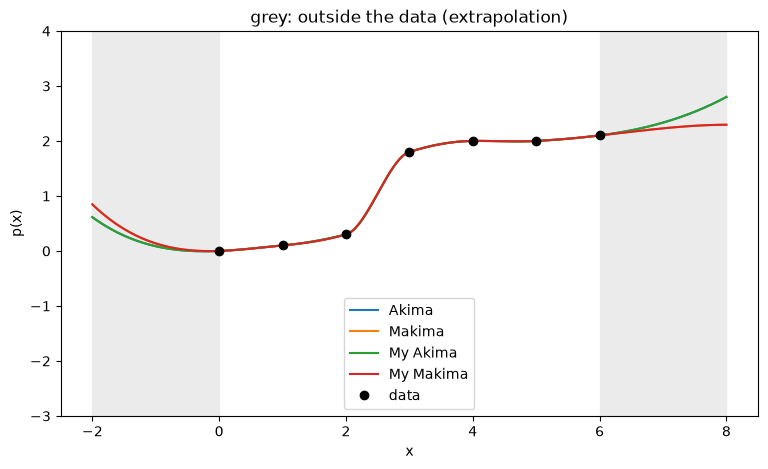

Akima derivatives: [0.05       0.10714286 0.29285714 0.37333333 0.01428571 0.06666667
 0.15      ]
Makima derivatives: [0.0375     0.10652174 0.33541667 0.35918367 0.01304348 0.05454545
 0.13      ]
My Akima derivatives: [0.05       0.10714286 0.29285714 0.37333333 0.01428571 0.06666667
 0.15      ]
My Makima derivatives: [0.0375     0.10652174 0.33541667 0.35918367 0.01304348 0.05454545
 0.13      ]
True
True


In [5]:
x = np.arange(7.)
h = np.array([0, 0.1, 0.3, 1.8, 2.0, 2.0, 2.1])

names = ["Akima", "Makima", "My Akima", "My Makima"]
methods = [lambda z:
           si.Akima1DInterpolator(x, h, extrapolate=True)(z),
           si.Akima1DInterpolator(x, h, method="makima", extrapolate=True),
           si.CubicHermiteSpline(x, h, my_akima(x, h), extrapolate=True),
           si.CubicHermiteSpline(x, h, my_makima(x, h), extrapolate=True)]

xnew = np.linspace(-2, 8, 401)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(-2, 0, color="0.92"); ax.axvspan(6, 8, color="0.92")   # extrapolation zones
for name, p in zip(names, methods):
    ax.plot(xnew, p(xnew), label=name)
ax.plot(x, h, "ko", label="data")
ax.set_ylim(-3, 4)
ax.set_xlabel("x"); ax.set_ylabel("p(x)")
ax.set_title("grey: outside the data (extrapolation)")
ax.legend()
plt.show()

print("Akima derivatives:", si.Akima1DInterpolator(x, h).derivative()(x))
print("Makima derivatives:", si.Akima1DInterpolator(x, h, method="makima").derivative()(x))
print("My Akima derivatives:", my_akima(x, h))
print("My Makima derivatives:", my_makima(x, h))

print(np.allclose(
    si.Akima1DInterpolator(x, h).derivative()(x),
    my_akima(x, h)
))

print(np.allclose(
    si.Akima1DInterpolator(x, h, method="makima").derivative()(x),
    my_makima(x, h)
))

**Test Case 2**

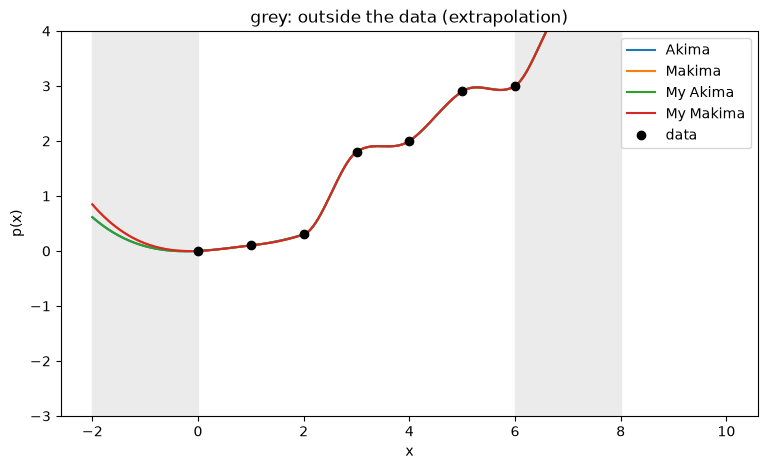

Akima derivatives: [ 0.05        0.10714286  0.29285714  0.655       0.63333333  0.63333333
  0.60909091  0.1         0.1         0.1        -0.05      ]
Makima derivatives: [ 0.0375      0.10652174  0.33541667  0.67794118  0.63623188  0.61014493
  0.62        0.16086957  0.1         0.06       -0.0375    ]
My Akima derivatives: [ 0.05        0.10714286  0.29285714  0.655       0.63333333  0.63333333
  0.60909091  0.1         0.1         0.1        -0.05      ]
My Makima derivatives: [ 0.0375      0.10652174  0.33541667  0.67794118  0.63623188  0.61014493
  0.62        0.16086957  0.1         0.06       -0.0375    ]
True
True


In [7]:
x = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10.])
h = np.array([0, 0.1, 0.3, 1.8, 2.0, 2.9, 3.0, 4.5, 4.6, 4.7, 4.7])

names = ["Akima", "Makima", "My Akima", "My Makima"]
methods = [lambda z:
           si.Akima1DInterpolator(x, h, extrapolate=True)(z),
           si.Akima1DInterpolator(x, h, method="makima", extrapolate=True),
           si.CubicHermiteSpline(x, h, my_akima(x, h), extrapolate=True),
           si.CubicHermiteSpline(x, h, my_makima(x, h), extrapolate=True)]

xnew = np.linspace(-2, 8, 401)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(-2, 0, color="0.92"); ax.axvspan(6, 8, color="0.92")   # extrapolation zones
for name, p in zip(names, methods):
    ax.plot(xnew, p(xnew), label=name)
ax.plot(x, h, "ko", label="data")
ax.set_ylim(-3, 4)
ax.set_xlabel("x"); ax.set_ylabel("p(x)")
ax.set_title("grey: outside the data (extrapolation)")
ax.legend()
plt.show()

print("Akima derivatives:", si.Akima1DInterpolator(x, h).derivative()(x))
print("Makima derivatives:", si.Akima1DInterpolator(x, h, method="makima").derivative()(x))
print("My Akima derivatives:", my_akima(x, h))
print("My Makima derivatives:", my_makima(x, h))

print(np.allclose(
    si.Akima1DInterpolator(x, h).derivative()(x),
    my_akima(x, h)
))

print(np.allclose(
    si.Akima1DInterpolator(x, h, method="makima").derivative()(x),
    my_makima(x, h)
))